# Daily soil-moisture skill of DART40 against ESA CCI (S0 vs S1)

Top-5 cm soil moisture of the DART40 ensemble mean, verified daily against ESA CCI over the DA scorecard windows: **16–31 Dec 2011 (DART40-S0)** and **16–31 May 2012 (DART40-S1)**.

Per land cell, on the days both are valid (≥ `min_days`):

* **anomaly correlation**: correlation of departures from each series' own window mean, testing day-to-day wetting and drying;
* **ubRMSE**: RMSE after removing the window-mean difference, insensitive to the model–satellite climatological offset. The figure marks the observed day-to-day variability (ESA CCI std) for comparison: ubRMSE close to it means little day-to-day skill.

Only DART40 has a soil-moisture time series in both seasons. No like-for-like no-DA control exists for these windows (the CTRL10 DA-period ELM output lacks soil moisture; the free-running CTRL runs differ in configuration, ensemble size and, for S0, year), so this compares seasons, not DA vs no DA. ESA CCI masks frozen and snow-covered soils, so S0 has little coverage poleward of ~40°N (grey on the maps).

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")   # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")   # land mask, soil-layer thickness
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
DZSOI_FILE = LAND_SUPPORT_DIR / "dzsoi_elm.nc"
LAND_FRACTION_FILE = LAND_SUPPORT_DIR / "landmask_1x1.nc"

# name -> season (registry DA run); a single-member case can be given as
# {"path": ..., "nens": 1, "member_dirs": False, "days": pd.date_range(...)}.
experiments = {"DART40-S0": {"season": "S0"}, "DART40-S1": {"season": "S1"}}
COLORS = {"DART40-S0": "#2166ac", "DART40-S1": "#b2182b"}
depth_cm = 5
min_days = 8
force_compute = False
fontsize = 14
FIGURE_DPI = 200
show = True

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from configs.output_paths import workflow_output_dirs
from util.bias_metrics import experiment_registry
from util.da_scorecard import window_days
from util.lnd_sm_daily_skill import (top_layer_weights, load_ensemble_top_sm, load_esa_cci,
                                     skill_maps, regional_summary, plot_sm_skill)

data_dir, figure_dir = workflow_output_dirs("analysis_lnd_model_evaluation", "sm_daily_skill", output_root=DIAGNOSTIC_OUTPUT_ROOT)
land = xr.load_dataset(LAND_FRACTION_FILE)["landfrac"].where(lambda f: f.lat >= -60)
weights = top_layer_weights(xr.load_dataset(DZSOI_FILE)["DZSOI"], depth_cm)
print(f"top {depth_cm} cm = layers {list(range(1, int(weights.notnull().any(['lat', 'lon']).sum()) + 1))}")

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


top 5 cm = layers [1, 2]


## 3. Skill maps (cached per experiment)

In [3]:
maps = {}
for name, spec in experiments.items():
    if "season" in spec:
        days = window_days(spec["season"])
        config = experiment_registry(INPUT_DATA_ROOT, spec["season"], "da")[name]
    else:
        days, config = spec["days"], spec
    path = data_dir / f"sm_daily_skill_{name}_top{depth_cm:02d}cm_{days[0]:%Y%m%d}-{days[-1]:%Y%m%d}_min{min_days}.nc"
    if path.is_file() and not force_compute:
        maps[name] = xr.load_dataset(path)
        print(f"[REUSE] {path.name}")
        continue
    mean, spread = load_ensemble_top_sm(config, days, weights.dropna("levgrnd", how="all"))
    obs = load_esa_cci(OBSERVATION_ROOT, days)
    ds = skill_maps(mean, obs, min_days=min_days)
    ds["spread"] = spread.mean("time").where(ds["r"].notnull())
    ds.attrs.update(experiment=name, window=f"{days[0]:%Y-%m-%d} to {days[-1]:%Y-%m-%d}",
                    members=int(config["nens"]), depth_cm=depth_cm, min_days=min_days, reference="ESA CCI daily")
    ds.to_netcdf(path)
    maps[name] = ds
    print(f"[WRITE] {path.name}")

[REUSE] sm_daily_skill_DART40-S0_top05cm_20111216-20111231_min8.nc
[REUSE] sm_daily_skill_DART40-S1_top05cm_20120516-20120531_min8.nc


sh: getfattr: command not found
sh: getfattr: command not found


## 4. Regional summary

In [4]:
summary = pd.concat([regional_summary(ds).assign(experiment=name) for name, ds in maps.items()], ignore_index=True)
summary.to_csv(data_dir / f"sm_daily_skill_summary_top{depth_cm:02d}cm.csv", index=False)
summary.pivot(index="region", columns="experiment", values=["r", "ubrmse", "cells"]).round(3)

r              ubrmse               cells          
experiment      DART40-S0 DART40-S1 DART40-S0 DART40-S1 DART40-S0 DART40-S1
region                                                                     
Global              0.302     0.358     0.018     0.020    4991.0    8206.0
NH extratropics     0.193     0.323     0.016     0.021    1842.0    5154.0
SH extratropics     0.563     0.440     0.024     0.016    1151.0    1051.0
Tropics             0.253     0.387     0.016     0.020    1998.0    2001.0

## 5. Figure

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/analysis_lnd_model_evaluation/sm_daily_skill/sm_daily_skill_DART40_S0_S1_top05cm.pdf


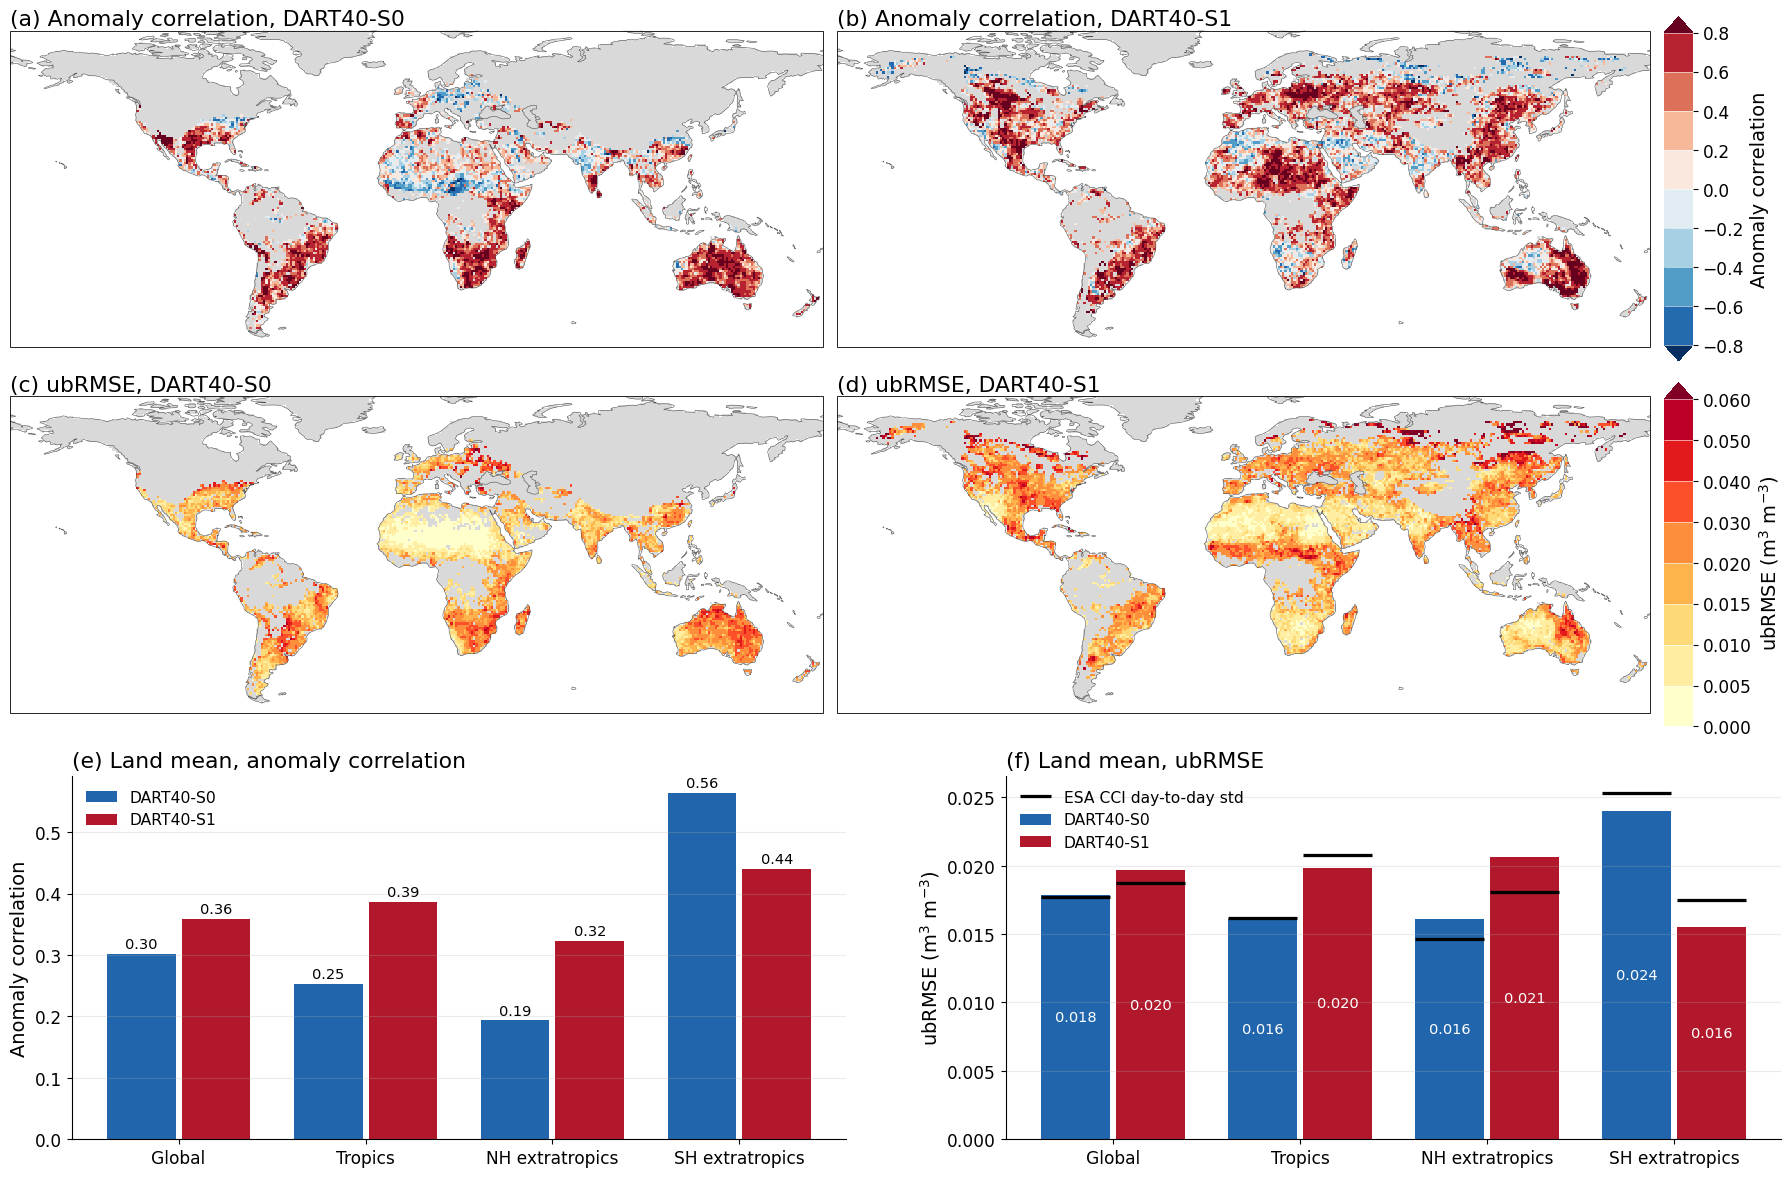

In [5]:
fig = plot_sm_skill(maps, summary, colors=COLORS, fontsize=fontsize, land=land)
output = figure_dir / f"sm_daily_skill_DART40_S0_S1_top{depth_cm:02d}cm.pdf"
fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
print(f"[FIGURE] {output}")
if not show:
    plt.close(fig)